# MPD 800 DC export: voltage and partial discharge

Imports the two exports and plots voltage versus elapsed time and signed PD charge versus elapsed time. The shared time origin is **02-Oct-2026 19:36:18.236 UTC** (from both CSV headers). Values are converted from V to kV and C to pC for display.

Requirements: `numpy`, `pandas`, and `matplotlib` in your Jupyter kernel. If needed, run `%pip install numpy pandas matplotlib` in a separate cell.

**Large files:** imports load all rows into RAM (about 16 bytes per row for the two numeric columns, plus parsing and plotting overhead). Hexbin reduces rendering cost but still processes every PD event. Scatter defaults to a reproducible sample of at most 200,000 events. Running this notebook reads the full exports; its creation used only the header and five data rows of each file.

In [4]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

def prompt_export_path(label):
    while True:
        filepath = input(f"Please enter the absolute filepath of your {label} .csv file: ")
        path = Path(filepath.strip().strip('"').strip("'"))
        if path.is_file():
            print(f"\n{label} Data Filepath: \"{path}\"")
            return path
        print("\nThe specified file does not exist. Please check the path and try again.")


VOLTAGE_PATH = prompt_export_path("MPD DC voltage")
PD_PATH = prompt_export_path("MPD partial discharge")

PD_PLOT = "hexbin"       # "hexbin" or "scatter"
PD_CHARGE_SCALE = "signed_log"  # "signed_log" or "linear", for either plot type
HEXBIN_GRIDSIZE = (250, 120)
MAX_SCATTER_POINTS = 200_000  # None plots every event
TIME_WINDOW = None       # Optional (start_seconds, end_seconds), e.g. (0, 600)


MPD DC voltage Data Filepath: "E:\AE_Data\PD-acoustic-EMPIRE-2026-10-02\PD-acoustic-EMPIRE_144_dcExport_MPD_800_1.1.1_voltage-2026-10-02_14h36m18s.csv"

MPD partial discharge Data Filepath: "E:\AE_Data\PD-acoustic-EMPIRE-2026-10-02\PD-acoustic-EMPIRE_144_dcExport_MPD_800_1.1.1_pd-2026-10-02_14h36m18s.csv"


In [5]:
def load_export(path, expected_value_suffix, value_name):
    """Validate the two-column schema and read numeric values without guessing types."""
    if not path.is_file():
        raise FileNotFoundError(f"CSV not found: {path}")
    columns = pd.read_csv(path, sep=";", nrows=0, encoding="utf-8-sig").columns.tolist()
    if (len(columns) != 2
            or not columns[0].startswith("Time [seconds since ")
            or not columns[1].endswith(expected_value_suffix)):
        raise ValueError(f"Unexpected columns in {path.name}: {columns}")
    frame = pd.read_csv(path, sep=";", encoding="utf-8-sig", dtype=np.float64)
    frame.columns = ["time_s", value_name]
    valid = np.isfinite(frame["time_s"]) & np.isfinite(frame[value_name])
    invalid_count = int((~valid).sum())
    if invalid_count:
        print(f"{path.name}: excluding {invalid_count:,} non-finite rows")
        frame = frame.loc[valid].copy()
    if frame.empty:
        raise ValueError(f"No finite data rows in {path}")
    if not frame["time_s"].is_monotonic_increasing:
        frame = frame.sort_values("time_s", kind="stable").reset_index(drop=True)
    print(f"{path.name}: {len(frame):,} rows; "
          f"time {frame['time_s'].min():.3f} to {frame['time_s'].max():.3f} s")
    return frame, columns[0]

voltage, voltage_time_header = load_export(VOLTAGE_PATH, "DC voltage [V]", "voltage_V")
pd_events, pd_time_header = load_export(PD_PATH, "PD charge [C]", "charge_C")
if voltage_time_header != pd_time_header:
    raise ValueError("Exports have different time origins; align their timestamps before plotting.")
print(f"Shared time reference: {voltage_time_header}")

PD-acoustic-EMPIRE_144_dcExport_MPD_800_1.1.1_voltage-2026-10-02_14h36m18s.csv: 790 rows; time 0.064 to 236.764 s
PD-acoustic-EMPIRE_144_dcExport_MPD_800_1.1.1_pd-2026-10-02_14h36m18s.csv: 21,775,681 rows; time 48.696 to 236.872 s
Shared time reference: Time [seconds since 02-Oct-2026 19:36:18.236 (UTC)]


Smallest absolute PD charge in selected time window: 10.0034329778 pC


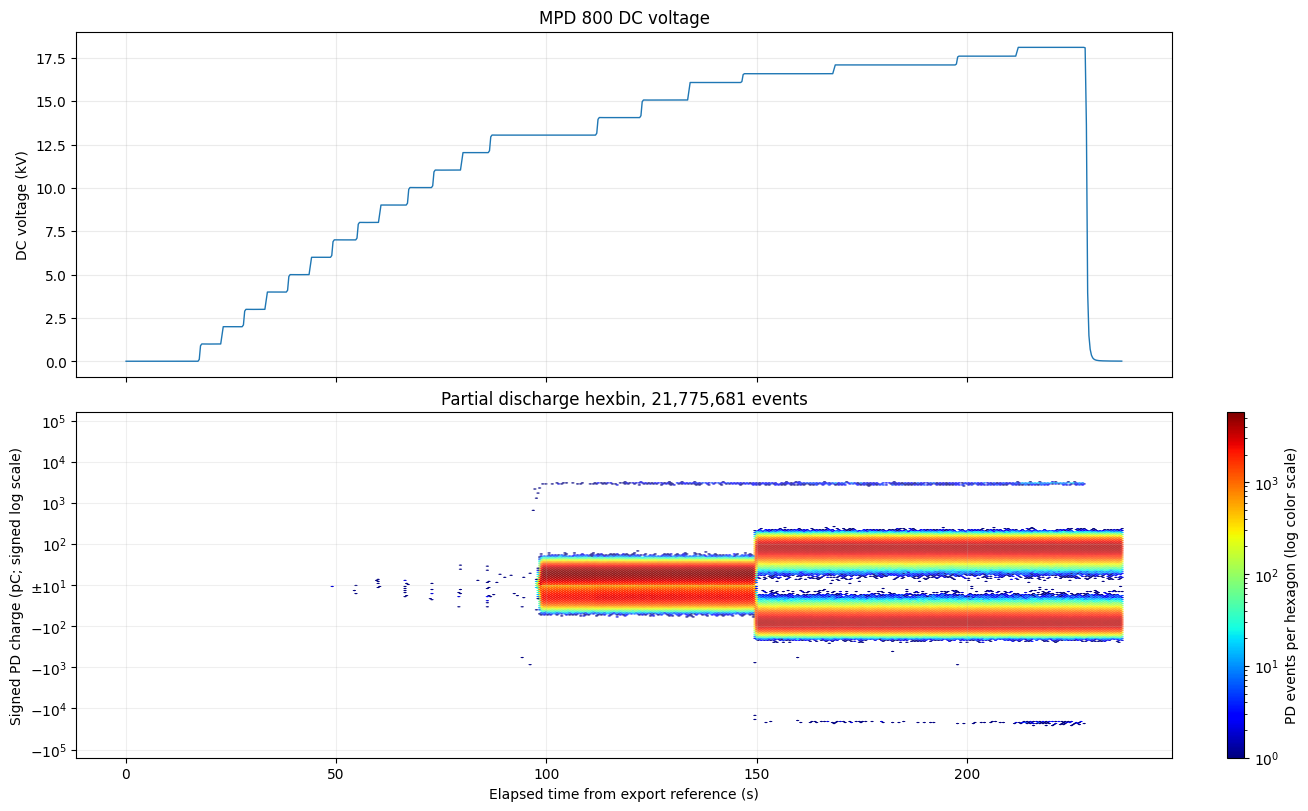

In [6]:
def select_time_window(frame):
    if TIME_WINDOW is None:
        return frame
    start, end = TIME_WINDOW
    if not np.isfinite([start, end]).all() or start >= end:
        raise ValueError("TIME_WINDOW must contain finite start < end values.")
    return frame.loc[frame["time_s"].between(start, end)]

voltage_view = select_time_window(voltage)
pd_view = select_time_window(pd_events)
if voltage_view.empty or pd_view.empty:
    raise ValueError("The selected time window must contain both voltage data and PD events.")
if PD_PLOT not in {"hexbin", "scatter"}:
    raise ValueError('PD_PLOT must be "hexbin" or "scatter".')

if PD_CHARGE_SCALE not in {"signed_log", "linear"}:
    raise ValueError('PD_CHARGE_SCALE must be "signed_log" or "linear".')

plot_time_s = pd_view["time_s"].to_numpy()
charge_pc = pd_view["charge_C"].to_numpy() * 1e12
min_abs_charge_pc = float(np.abs(charge_pc).min())
print(f"Smallest absolute PD charge in selected time window: {min_abs_charge_pc:.12g} pC")
if PD_CHARGE_SCALE == "signed_log":
    # Match EasyAE: remove exact zeros, log10 the magnitude, then restore its sign.
    nonzero = charge_pc != 0
    zero_count = int((~nonzero).sum())
    if not nonzero.any():
        raise ValueError('Signed log charge needs nonzero PD events; set PD_CHARGE_SCALE = "linear" to show zeros.')
    if zero_count:
        plot_time_s = plot_time_s[nonzero]
        charge_pc = charge_pc[nonzero]
        print(f"Signed log charge: excluding {zero_count:,} exact-zero events.")
        min_nonzero_charge_pc = float(np.abs(charge_pc).min())
        print(f"Smallest nonzero absolute PD charge: {min_nonzero_charge_pc:.12g} pC")
    log_abs = np.log10(np.abs(charge_pc))
    exp_min = int(np.floor(log_abs.min()))
    exp_max = int(np.ceil(log_abs.max()))
    plot_charge = np.sign(charge_pc) * (log_abs - exp_min)
    # Leave visible space even if every pulse is at the reference magnitude.
    charge_extent = max(exp_max - exp_min, 1)
    charge_ylabel = "Signed PD charge (pC; signed log scale)"
else:
    plot_charge = charge_pc
    charge_extent = float(np.abs(charge_pc).max())
    charge_extent = charge_extent if charge_extent > 0 else 1.0
    charge_ylabel = "Signed PD charge (pC)"

# Keep raw imported charges intact; both views use the same plotting coordinates.
pd_plot_data = pd.DataFrame({"time_s": plot_time_s, "charge": plot_charge}, copy=False)

fig, (ax_voltage, ax_pd) = plt.subplots(
    2, 1, figsize=(13, 8), sharex=True, constrained_layout=True
)
ax_voltage.plot(voltage_view["time_s"], voltage_view["voltage_V"] * 1e-3,
                linewidth=1, color="tab:blue")
ax_voltage.set(ylabel="DC voltage (kV)", title="MPD 800 DC voltage")
ax_voltage.grid(alpha=0.25)

if PD_PLOT == "hexbin":
    density = ax_pd.hexbin(
        pd_plot_data["time_s"], pd_plot_data["charge"],
        gridsize=HEXBIN_GRIDSIZE, bins="log", mincnt=1, cmap="jet",
        linewidths=0, rasterized=True,
    )
    fig.colorbar(density, ax=ax_pd, label="PD events per hexagon (log color scale)")
    title = f"Partial discharge hexbin, {len(pd_plot_data):,} events"
else:
    if MAX_SCATTER_POINTS is not None:
        if not isinstance(MAX_SCATTER_POINTS, int) or MAX_SCATTER_POINTS <= 0:
            raise ValueError("MAX_SCATTER_POINTS must be a positive integer or None.")
    sample = (pd_plot_data.sample(n=MAX_SCATTER_POINTS, random_state=42)
              if MAX_SCATTER_POINTS is not None and len(pd_plot_data) > MAX_SCATTER_POINTS
              else pd_plot_data)
    ax_pd.scatter(sample["time_s"], sample["charge"],
                  s=2, alpha=0.35, color="tab:purple", linewidths=0, rasterized=True)
    title = f"Partial discharge scatter, {len(sample):,} of {len(pd_plot_data):,} events"

ax_pd.set(xlabel="Elapsed time from export reference (s)",
          ylabel=charge_ylabel, title=title)
if PD_CHARGE_SCALE == "signed_log":
    ticks = np.arange(-charge_extent, charge_extent + 1)
    labels = [
        f"$10^{{{exp_min + t}}}$" if t > 0 else
        f"$-10^{{{exp_min + abs(t)}}}$" if t < 0 else
        rf"$\pm10^{{{exp_min}}}$"
        for t in ticks
    ]
    ax_pd.set_yticks(ticks, labels=labels)
# Bounds use every displayed event, including extremes missed by sampled scatter.
ax_pd.set_ylim(-charge_extent * 1.05, charge_extent * 1.05)
ax_pd.grid(alpha=0.2)
if TIME_WINDOW is not None:
    ax_pd.set_xlim(*TIME_WINDOW)
plt.show()

`PD_CHARGE_SCALE = "signed_log"` applies the same signed, shifted base-10 transform as the EasyAE PD hexbin plot: `sign(q) * (log10(abs(q)) - exp_min)`, with `q` in pC and `exp_min` the floor of the smallest nonzero log magnitude in the selected interval. Positive pulses appear above the center and negative pulses below it; each tick away from the center is one decade in magnitude. The center tick denotes both positive and negative reference magnitudes, **not zero charge**. Exact-zero events are excluded from this view and their count is reported. A selected interval containing only zero-charge events requires the linear setting. Set `PD_CHARGE_SCALE = "linear"` and rerun the plotting cell to restore the original charge axis.

Change `PD_PLOT` to `"scatter"` in the configuration cell and rerun the plotting cell to compare views with the same charge scale. Hexbin colors show event counts, with logarithmic coloring independent of the charge scale. Scatter sampling can miss rare extremes; use hexbin or set `MAX_SCATTER_POINTS = None` to include every plotted event. `TIME_WINDOW` limits the displayed interval after import; signed-log reference magnitudes and limits are calculated from that full interval before scatter sampling.

Optional: uncomment the next cell to save the current figure beside the notebook.

In [7]:
# fig.savefig("MPD_DC_voltage_and_PD.png", dpi=200, bbox_inches="tight")